In [1]:
!pip -q install -U ultralytics pyyaml

In [9]:
from pathlib import Path
import yaml

# Dataset root (Input - Read Only)
DATA_ROOT = Path("/kaggle/input/datasets/tejaswinirj/problem/skin_problems") 

# Working directory (Output - Writable)
WORKING_ROOT = Path("/kaggle/working")

# Verify dataset folders
for split in ["train", "valid", "test"]:
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    if not image_dir.exists():
        raise FileNotFoundError(f"Images folder not found: {image_dir}")
    if not label_dir.exists():
        raise FileNotFoundError(f"Labels folder not found: {label_dir}")
    print(f"{split}: {len(list(image_dir.glob('*')))} images, {len(list(label_dir.glob('*.txt')))} label files")

# Data configuration (Keep absolute paths to the read-only input folder)
data_config = {
    "path": str(DATA_ROOT),  # Points to the read-only dataset
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 5,
    "names": ["Acne", "Dark Circle", "Pigmentation", "Spots", "Wrinkle"]
}

# Save the YAML file to the writable working directory
TRAIN_YAML = WORKING_ROOT / "data.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data_config, f, sort_keys=False, allow_unicode=True)

print("\nUpdated YAML:")
print(TRAIN_YAML.read_text())


train: 782 images, 782 label files
valid: 50 images, 50 label files
test: 30 images, 30 label files

Updated YAML:
path: /kaggle/input/datasets/tejaswinirj/problem/skin_problems
train: train/images
val: valid/images
test: test/images
nc: 5
names:
- Acne
- Dark Circle
- Pigmentation
- Spots
- Wrinkle



Polygon instance counts (not image counts): {'Acne': 1371, 'Pigmentation': 311, 'Spots': 233, 'Wrinkle': 695, 'Dark Circle': 182}
Images missing a label file: 0
Potentially invalid label lines: 0


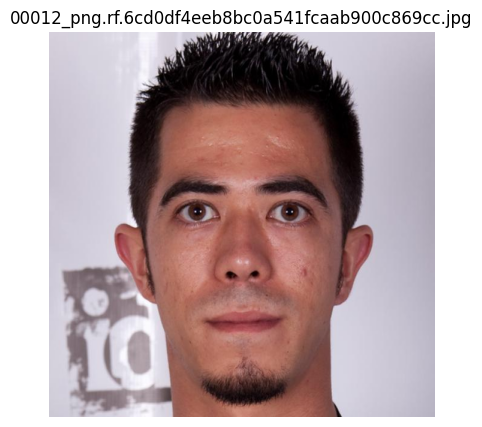

In [10]:
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

CLASS_NAMES = data_config["names"]
class_counts = Counter()
invalid_lines = []
missing_label_images = []

for split in ("train", "valid", "test"):
    img_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    for img_path in img_dir.iterdir():
        if img_path.suffix.lower() not in {".jpg",".jpeg",".png",".bmp",".webp"}:
            continue
        label_path = label_dir / f"{img_path.stem}.txt"
        if not label_path.exists():
            missing_label_images.append(str(img_path))
            continue
        for line_no, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), 1):
            parts = line.split()
            if not parts:
                continue
            try:
                cls = int(parts[0])
                if 0 <= cls < len(CLASS_NAMES):
                    class_counts[CLASS_NAMES[cls]] += 1
                else:
                    invalid_lines.append((str(label_path), line_no, "class id out of range"))
                if len(parts) < 7 or (len(parts) - 1) % 2 != 0:
                    invalid_lines.append((str(label_path), line_no, "polygon should have class + x/y pairs"))
            except Exception:
                invalid_lines.append((str(label_path), line_no, "could not parse label"))
print("Polygon instance counts (not image counts):", dict(class_counts))
print("Images missing a label file:", len(missing_label_images))
print("Potentially invalid label lines:", len(invalid_lines))
if invalid_lines[:5]:
    print("Examples:", invalid_lines[:5])

sample_images = list((DATA_ROOT / "train" / "images").glob("*"))
sample_images = [p for p in sample_images if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}]
if sample_images:
    p = sample_images[0]
    plt.figure(figsize=(7,5))
    plt.imshow(Image.open(p).convert("RGB"))
    plt.title(p.name)
    plt.axis("off")
    plt.show()

In [11]:
import torch
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Lightweight segmentation checkpoint. Ultralytics downloads pretrained weights.
# If you want a larger model and have enough GPU memory, consider yolo11s-seg.pt.
MODEL_NAME = "yolo11n-seg.pt"

model = YOLO(MODEL_NAME)
results = model.train(
    data=str(TRAIN_YAML),
    epochs=100,
    imgsz=640,
    batch=8,
    patience=20,
    device=0 if torch.cuda.is_available() else "cpu",
    workers=2,
    project=str(WORK_ROOT / "skin_problem_runs"),
    name="yolo11n_seg",
    pretrained=True,
    plots=True,
    save=True,
    exist_ok=True,
    seed=42,
    deterministic=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, flipl

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      1.77G      2.605      3.714      2.974       1.74          0         21        640: 100% ━━━━━━━━━━━━ 98/98 6.9it/s 14.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.2it/s 0.6s0.3s
                   all         50        207      0.302      0.331      0.129     0.0555      0.285      0.277     0.0953     0.0344

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      1.77G       2.58      3.723      2.722      1.766          0         30        640: 100% ━━━━━━━━━━━━ 98/98 7.0it/s 14.0s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.9it/s 0.7s0.3s
                   all         50        207      0.291      0.157      0.119     0.0447      0.281      0.129      0.115     0.0438



In [12]:
best_path = WORK_ROOT / "skin_problem_runs" / "yolo11n_seg" / "weights" / "best.pt"
if not best_path.exists():
    raise FileNotFoundError(f"Trained weights not found: {best_path}")

best_model = YOLO(str(best_path))
test_metrics = best_model.val(
    data=str(TRAIN_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    plots=True,
    project=str(WORK_ROOT / "skin_problem_test_eval"),
    name="test",
    exist_ok=True,
)
print(test_metrics)

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,850,439 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.0 ms, read: 65.1±9.7 MB/s, size: 39.4 KB)
val: Scanning /kaggle/input/datasets/tejaswinirj/problem/skin_problems/test/labels... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 591.4it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/tejaswinirj/problem/skin_problems/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3s/it 5.3s1.6ss
                   all         30        157      0.455      0.298      0.176     0.0514      0.625      0.173       0.17     0.0446
                  Acne         23        104      0.172      0.683      0.352     0.0937      0.283      0.462      0.345     0.0876
          Pigmentat

In [13]:
test_images = list((DATA_ROOT / "test" / "images").glob("*"))
test_images = [p for p in test_images if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}]
if test_images:
    preview = best_model.predict(
        source=[str(p) for p in test_images[:6]],
        imgsz=640,
        conf=0.25,
        save=True,
        project=str(WORK_ROOT / "skin_problem_predictions"),
        name="preview",
        exist_ok=True,
    )
    print("Prediction visualizations saved under /kaggle/working/skin_problem_predictions/preview")
else:
    print("No test images found.")


0: 640x640 2 Acnes, 1 Dark Circle, 1 Wrinkle, 6.8ms
1: 640x640 (no detections), 6.8ms
2: 640x640 4 Wrinkles, 6.8ms
3: 640x640 1 Acne, 6.8ms
4: 640x640 1 Acne, 6.8ms
5: 640x640 1 Acne, 6.8ms
Speed: 1.1ms preprocess, 6.8ms inference, 4.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/skin_problem_predictions/preview
Prediction visualizations saved under /kaggle/working/skin_problem_predictions/preview


In [14]:
# Bundle weights and the class/data configuration for download from Kaggle Output.
PACKAGE_DIR = WORK_ROOT / "skin_problem_model"
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(best_path, PACKAGE_DIR / "best.pt")
shutil.copy2(TRAIN_YAML, PACKAGE_DIR / "data.yaml")

metadata = {
    "framework": "Ultralytics YOLO segmentation",
    "checkpoint": "best.pt",
    "class_names": CLASS_NAMES,
    "input_image_size_used_for_training": 640,
    "dataset_license": "CC BY 4.0",
    "dataset_source": "https://universe.roboflow.com/hetvi-eww-zdjt2/skin-problem-image-segmentation-02/dataset/3",
}
with open(PACKAGE_DIR / "model_info.json", "w", encoding="utf-8") as f:
    import json
    json.dump(metadata, f, indent=2)

zip_path = WORK_ROOT / "skin_problem_model.zip"
if zip_path.exists():
    zip_path.unlink()
shutil.make_archive(str(zip_path.with_suffix("")), "zip", root_dir=PACKAGE_DIR)
print("Model package created:", zip_path)
print("Files:", [p.name for p in PACKAGE_DIR.iterdir()])

Model package created: /kaggle/working/skin_problem_model.zip
Files: ['data.yaml', 'model_info.json', 'best.pt']
